In [1]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.constants as const
import os, sys
import h5py

import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.lines as mlines

from sod_crinjection import velocity as sodcr_velocity
from sod_crinjection import pressure as sodcr_pressure
from sod_crinjection import density as sodcr_density
from sod_crinjection import shock_loc as sodcr_shock_loc
from sod_crinjection import pressure_cr as sodcr_pressure_cr
from sod_crinjection import pressure_thermal as sodcr_pressure_th

fig_dir = "../../figures/"

flash_output_dir = "/home/watanabe/Projects/meerkat_bowshocks/outputs/"

List the things common to each simulation

In [2]:
# fixed for our 3D simulation
nxb = 8
nyb = 8
nzb = 1

# parameters to read
params = ["dens", "velx", "pres", "shma" ]
thetaBs = [30,45,60]

open sod results 

since we save at each 0.01 s, to get t = 0.35 we read plot file 035

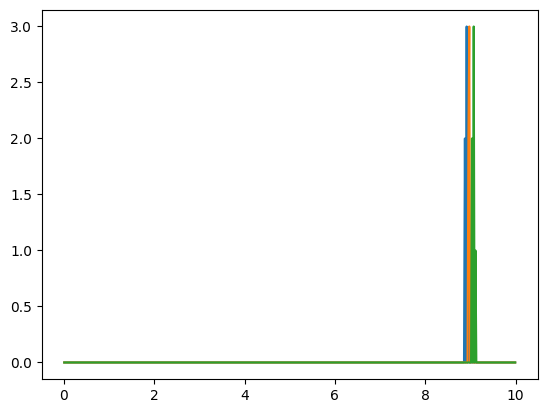

In [3]:
sim_params_arr = []
sim_pres_arr = []
sim_xcoords_arr = []
times = []
xs_data = []

for thetaB in thetaBs:

    file_name = os.path.join(flash_output_dir, f"Sod_MHD_mgob{thetaB}", "sod_hdf5_plt_cnt_0007")

    params_arr = []

    with h5py.File(file_name) as f:
        
        bbox = f["bounding box"][()]
        node_type = f["node type"][()]

        times.append(f["real scalars"][()][0][1])
        # print(time)

        # computing cell size
        low_corner = bbox[:,:,0]
        cell_dx = f["block size"][()][:,0] / nxb
        cell_dy = f["block size"][()][:,1] / nyb
        cell_dz = f["block size"][()][:,2] / nzb
        cell_d = np.array((cell_dx,cell_dy,cell_dz))

        # meshgrid of cell sizes
        k,j,i = np.meshgrid(range(nzb),range(nyb),range(nxb), indexing='ij')
        
        # mask to get all leaf nodes (those with max refinement in each block)
        leafmask = node_type == 1

        # x coordinate at lead node
        xcoord = low_corner[leafmask,0,None,None,None] + cell_dx[leafmask,None,None,None]*(.5+i[None,])
        # ycoord = low_corner[leafmask,1,None,None,None] + cell_dy[leafmask,None,None,None]*(.5+j[None,])
        # zcoord = low_corner[leafmask,2,None,None,None] + cell_dz[leafmask,None,None,None]*(.5+k[None,])

        xcoord_arr = np.mean(xcoord, axis=(1,2)).flatten()

        # get indices according to increasing x
        xsorted_idces = np.argsort(xcoord_arr)
        
        for k, param in enumerate(params):

            if param == "pres":
                all_pres_arr = []

                pres_arr = (np.mean(f["pres"][()][leafmask], axis=(1,2)).flatten())[xsorted_idces]
                pth_arr = (np.mean(f["pres"][()][leafmask], axis=(1,2)).flatten())[xsorted_idces]
                pmag_arr =  (
                        ( (np.mean(f["magx"][()][leafmask], axis=(1,2)).flatten())[xsorted_idces]**2 + \
                                    (np.mean(f["magy"][()][leafmask], axis=(1,2)).flatten())[xsorted_idces]**2) * u.G**2  \
                                            / (2 * const.mu0.si)).to(u.g / (u.cm * u.s**2)).value
                

                pres_arr += pmag_arr

                prcr_arr = (np.mean(f["prcr"][()][leafmask], axis=(1,2)).flatten())[xsorted_idces]
                pres_arr += prcr_arr

                # print(pres_arr.min(), pres_arr.max())

                # sort based on increasing x
                all_pres_arr.append(pres_arr)
                all_pres_arr.append(pth_arr)
                all_pres_arr.append(pmag_arr)
                all_pres_arr.append(prcr_arr)

                sim_pres_arr.append(all_pres_arr)

                
                params_arr.append(pres_arr)

            else:
                param_single_arr = np.mean(f[param][()][leafmask], axis=(1,2)).flatten()
                params_arr.append(param_single_arr[xsorted_idces])

        # finally sort the xcoord array as well
        xcoord_arr = xcoord_arr[xsorted_idces]
        plt.plot(xcoord_arr, np.mean(f["shck"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces])

        shma_data = np.mean(f["shma"][()][leafmask], axis=(1,2)).flatten()[xsorted_idces]
        shma_data = shma_data[shma_data > 0]
        xs_data.append(np.mean((1.667 + 1) * shma_data**2 / (2 + (1.667 - 1) * shma_data**2)))

    if len(params_arr) != 0:
        sim_params_arr.append(params_arr)
        sim_xcoords_arr.append(xcoord_arr)
    

In [4]:
xs_data

[3.8735693, 3.874957, 3.8812218]

In [5]:
def craccel_mgob(theta_B, theta_crit=np.pi/4, delta_B=np.pi/18):
    '''As in Pais et al 2018'''
    return 0.5 * (np.tanh((theta_crit - theta_B) / delta_B) + 1)

In [6]:
# compute analytical density
xmid = 5.0
xthr_arr = np.linspace(-xmid, xmid, 100)
craccel_mach_val = 0.5  # constant in all runs 

sim_params_thr_arr = np.zeros((len(thetaBs), len(params), len(xthr_arr)))
sim_params_pres_arr = np.zeros((len(thetaBs), 2, len(xthr_arr)))

# mach_thr = [9.56, 9.78, 10.0]
x0s = [4.5, 4.0, 3.8]
for i, thetaB in enumerate(thetaBs):
    # compute CR to thermal ratio, used for calculation of initail resutls
    craccel_mgob_val = craccel_mgob(np.deg2rad(thetaB))
    # print(craccel_mgob_val)
    craccel = craccel_mgob_val * craccel_mach_val
    print(craccel)
    cr_thermal_ratio = craccel / (1.0 - craccel)
    initial_args_cr = (1.667, 1.3333, cr_thermal_ratio, 0.1, 63.499, 0.125, 1.0)

    for k, param in enumerate(params):
        
        if param == "dens":
            sim_params_thr_arr[i,k,:] = sodcr_density(xthr_arr, times[i], x0 = x0s[i], init_args=initial_args_cr)

        if param == "pres":
            sim_params_thr_arr[i,k,:] = sodcr_pressure(xthr_arr, times[i], x0 = x0s[i], init_args=initial_args_cr)

        if param == "velx":
            sim_params_thr_arr[i,k,:] = sodcr_velocity(xthr_arr, times[i], x0 = x0s[i], init_args=initial_args_cr)

        if param == "shma":
            # find shock location
            xshock = sodcr_shock_loc(xthr_arr, times[i], x0 = x0s[i], init_args=initial_args_cr, atol=5e-2)[0]
            print(xshock + xmid)
            shock_loc_idx = np.digitize(xshock, xthr_arr, right=True)
            sim_params_thr_arr[i,k,shock_loc_idx] = 9.56

    sim_params_pres_arr[i,0,:] = sodcr_pressure_th(xthr_arr, times[i], x0 = x0s[i], init_args=initial_args_cr)
    sim_params_pres_arr[i,1,:] = sodcr_pressure_cr(xthr_arr, times[i], x0 = x0s[i], init_args=initial_args_cr)

0.4762870634112166
8.88888888888889
0.25
8.98989898989899
0.0237129365887834
9.09090909090909


30
45
60


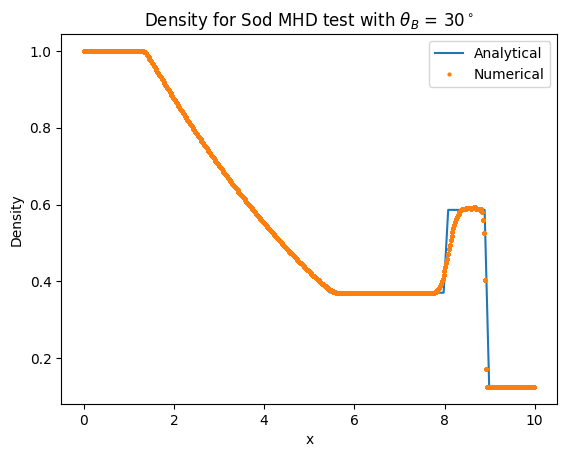

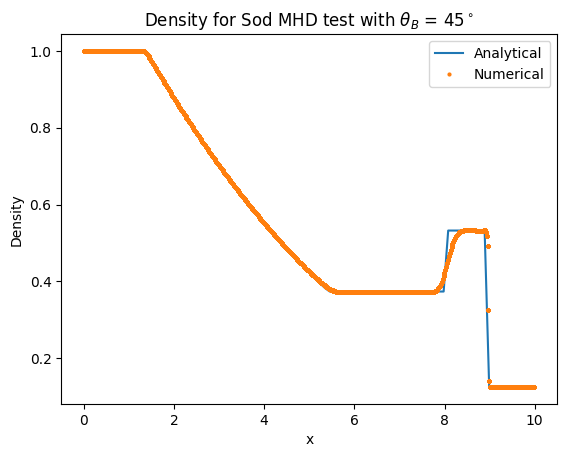

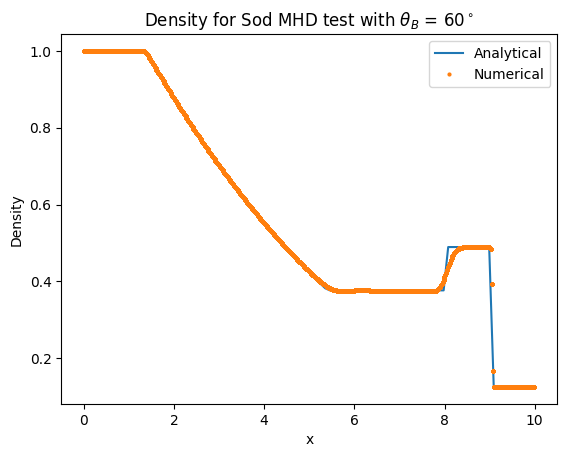

In [7]:
for i, thetaB in enumerate(thetaBs):
    print(thetaB)
    fig, ax = plt.subplots()
    for k, param in enumerate(params):
        if param != "dens":
            continue
        ax.plot(xthr_arr + xmid, sim_params_thr_arr[i,k,:], label="Analytical")
        ax.plot(xcoord_arr, sim_params_arr[i][k], ls="", marker="o", ms=2.0, label="Numerical")
    
    ax.legend()
    ax.set_xlabel("x")
    ax.set_ylabel("Density")
    ax.set_title(rf"Density for Sod MHD test with $\theta_B$ = {thetaB}$^\circ$")



now for plotting the pressure only

In [23]:
pres_colors = ["royalblue", "orangered", "violet", "forestgreen"]


# create legend handles for pressure
pres_handles = [
    mlines.Line2D([0], [0],
                mec=pres_colors[0],
                mfc=pres_colors[0],
                marker="x",
                ls = "-",
                color=pres_colors[0],
                lw=2.0,
                mew=3.0,
                markersize=12,
                alpha=1.0,
                label=r"$P_\mathrm{tot}$"),
    mlines.Line2D([0], [0],
                mec=pres_colors[1],
                mfc=pres_colors[1],
                marker="x",
                ls = "-",
                color=pres_colors[1],
                lw=2.0,
                mew=3.0,
                markersize=12,
                alpha=1.0,
                label=r"$P_\mathrm{th}$"),

    mlines.Line2D([0], [0],
                mec=pres_colors[3],
                mfc=pres_colors[3],
                marker="x",
                ls = "-",
                color=pres_colors[3],
                lw=2.0,
                mew=3.0,
                markersize=12,
                alpha=1.0,
                label=r"$P_\mathrm{CR}$"),
]

pres_xlims = [(-0.05, 10.5), (-0.05, 10.5)]
pres_ylims = [(-0.05, 70), (1e-10, 5e0)]

marker_sizes = [3.0, 6.0]

region_filters = [1, 1]


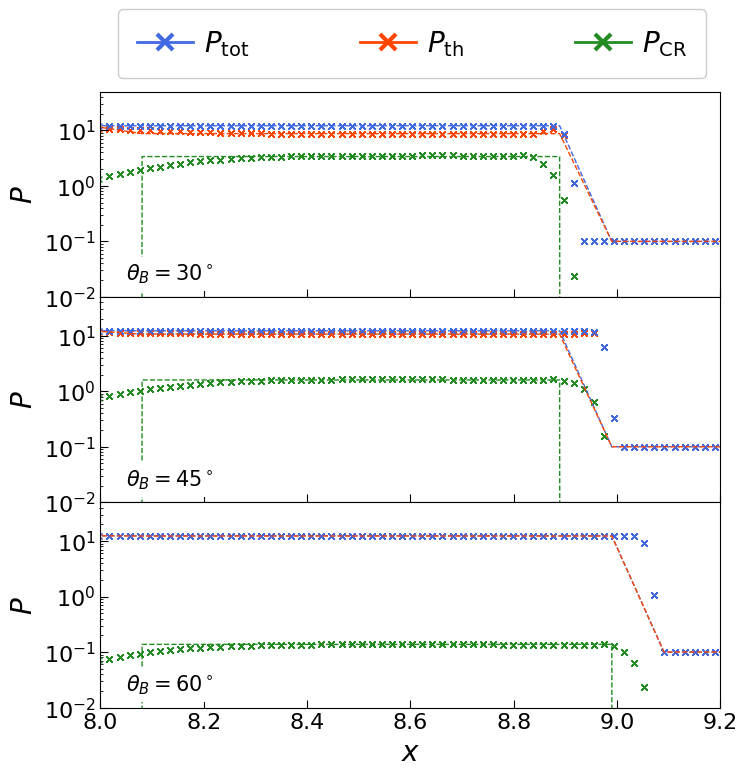

In [39]:

fig = plt.figure(figsize=(8,8))
gs = fig.add_gridspec( len(thetaBs), hspace=0, wspace=0.25)

axs = gs.subplots(sharex=False, sharey=False)

for i, thetaB in enumerate(thetaBs):


    # plot CR and thermal components seperately
    ptot_arr, pth_arr, pmag_arr, pcr_arr = sim_pres_arr[i]

    axs[i].plot(sim_xcoords_arr[i], ptot_arr, ls="", lw=1.0, marker="x", color=pres_colors[0], ms=5.0, label=r"$P_\mathrm{tot}$", zorder=1, rasterized=True)
    axs[i].plot(sim_xcoords_arr[i], pth_arr, ls="", lw=1.0,marker="x", color=pres_colors[1], ms=5.0, label=r"$P_\mathrm{th}$", zorder=0, rasterized=True)
    axs[i].plot(sim_xcoords_arr[i], pmag_arr, ls="", lw=1.0,marker="x", color=pres_colors[2], ms=5.0, label=r"$P_\mathrm{mag}$", zorder=0, rasterized=True)
    axs[i].plot(sim_xcoords_arr[i], pcr_arr, ls="", lw=1.0,marker="x", color=pres_colors[3],ms=5.0, label=r"$P_\mathrm{CR}$", rasterized=True)

    # plot analytical solution
    axs[i].plot(xthr_arr+ xmid, sim_params_thr_arr[i,2,:], ls="--", lw=1.0, color=pres_colors[0], rasterized=True)
    axs[i].plot(xthr_arr+ xmid, sim_params_pres_arr[i,0,:], ls="--", lw=1.0, color=pres_colors[1], rasterized=True)
    axs[i].plot(xthr_arr+ xmid, sim_params_pres_arr[i,1,:], ls="--", lw=1.0, color=pres_colors[3], rasterized=True)

    # limits
    axs[i].set_xlim((8., 9.2))
    axs[i].set_ylim((1e-2, 50))

    axs[i].annotate(rf"$\theta_B = {thetaB}^\circ$", xy=(8.05, 2e-2), fontsize=15, bbox=dict(facecolor='white', edgecolor='none'))

    # external configurations
    # axs[i].label_outer()   # to ignore labels inside

    # x
    if i == len(thetaBs) - 1:
        axs[i].set_xlabel("$x$", fontsize=20)
        axs[i].tick_params(axis='x', direction="in", which='major', size=6, labelsize=16)
        axs[i].tick_params(axis='x', direction="in", which='minor', size=4, labelsize=14)
    else:
        # axs[i].set_xlabel("", fontsize=18)
        axs[i].tick_params(axis='x', direction="in", which='major', size=6, labelsize=0)
        axs[i].tick_params(axis='x', direction="in", which='minor', size=4, labelsize=0)

    # y
    axs[i].set_ylabel(r"$P$", fontsize=20)
    axs[i].set_yscale("log")
    # axs[i].set_yticks([1e-1, 1e-0, 1e-1], labels=["$10^{-9}$", "$10^{-5}$", "$10^{-1}$"])
    # axs[i].set_yticks([1e-7, 1e-3], labels=[], minor=True)

    # if j == 0:
    #     axs[i].set_yticks([0.0, 0.5, 1.0], labels=[0.0, 0.5, 1.0])
    #     axs[i].set_yticks([0.25, 0.75], labels=[], minor=True)
    #     # axs[i].set_yticklabels([0.0, 0.25, 0.5, 0.75, 1.0], minor=True)
    # elif j == 1:
    #     axs[i].set_yscale("log")
    #     axs[i].set_yticks([1e-9, 1e-5, 1e-1], labels=["$10^{-9}$", "$10^{-5}$", "$10^{-1}$"])
    #     axs[i].set_yticks([1e-7, 1e-3], labels=[], minor=True)


    axs[i].tick_params(axis='y', direction="in", which='major', size=6, labelsize=16)
    axs[i].tick_params(axis='y', direction="in", which='minor', size=2, labelsize=14)

fig.legend(handles=pres_handles, bbox_to_anchor=(0.9, 1.0), ncols=4, fontsize=20, framealpha=1.0, columnspacing=4.0, borderpad=0.7, borderaxespad=0.5, labelspacing=0.5, handletextpad=0.4)

# fig.savefig(os.path.join("/home/watanabe/Projects/meerkat_bowshocks/figures/sod_crinj", "sod_mgob_pres.pdf"), dpi=300, bbox_inches="tight")